# A first binary spinodal simulation

I calculate a dimensionless Cahn–Hilliard model with bulk energy (c²−1)²/4. c is the conserved field, not an SI concentration. The mobility and gradient coefficient are both 1, the grid spacing is 1, dt=0.2 and the random seed is 42. The nonlinear bulk term is explicit. Energy decrease alone does not establish numerical convergence.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## 1. Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy pillow matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## 2. Choose the input values

I retain the default values from the original calculation. The output name locates the files written by this notebook.

In [2]:
n = 128
dt = 0.2
steps = 1600
seed = 42
output = 'spinodal-results'

## 3. Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [3]:
from pathlib import Path
import csv
import numpy as np
from PIL import Image

## 4. Set up the Fourier grid

I calculate wave numbers consistent with the grid spacing and periodic domain. k2 denotes the squared magnitude of a wave vector. The denominator contains the term treated implicitly in the original update. The zero Fourier mode represents the spatial mean.

In [4]:
output = Path(output)
output.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(seed)
c = 0.04 * rng.standard_normal((n, n))
c -= c.mean()
k = 2 * np.pi * np.fft.fftfreq(n, d=1.0)
kx, ky = np.meshgrid(k, k, indexing='ij')
k2 = kx * kx + ky * ky
initial_mean = c.mean()

## 5. Prepare the next part of the calculation

I define `history`, `snapshots`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [5]:
history = []
snapshots = {100: 1, 400: 2, steps: 3}

## 6. Define diagnostics

I define this operation before calling it. I keep its arguments explicit so I can test it separately.

In [6]:
def diagnostics(field):
    spectrum = np.fft.fft2(field)
    gx = np.fft.ifft2(1j * kx * spectrum).real
    gy = np.fft.ifft2(1j * ky * spectrum).real
    energy = np.mean((field * field - 1) ** 2 / 4 + (gx * gx + gy * gy) / 2)
    return (float(field.mean()), float(energy))

## 7. Prepare the next part of the calculation

I define `stops`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [7]:
stops = np.array([[0, 0, 255], [0, 255, 255], [0, 255, 0], [255, 255, 0], [255, 0, 0]])

## 8. Advance the field and record the result

I apply the update in its original order. I record the mean, energy or other diagnostics at the specified intervals. I do not clip the numerical field. A saved picture is a display of the field, not a substitute for a conservation check.

In [8]:
for step in range(steps + 1):
    if step % 10 == 0:
        mean, energy = diagnostics(c)
        history.append((step, step * dt, mean, energy))
    if step in snapshots:
        v = np.clip((c + 1) / 2, 0, 1)
        rgb = np.stack([np.interp(v, [0, 0.25, 0.5, 0.75, 1], stops[:, j]) for j in range(3)], axis=-1)
        img = Image.fromarray(np.rint(rgb).astype('uint8'))
        img.resize((640, 640), Image.Resampling.BICUBIC).save(output / f'spinodal-{snapshots[step]}.png')
    if step == steps:
        break
    c_hat = np.fft.fft2(c)
    bulk_hat = np.fft.fft2(c * c * c - c)
    c = np.fft.ifft2((c_hat - dt * k2 * bulk_hat) / (1 + dt * k2 * k2)).real
    if not np.isfinite(c).all():
        raise RuntimeError('Non-finite solution; reduce the time step.')

## 9. Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [9]:
with (output / 'diagnostics.csv').open('w', newline='') as stream:
    writer = csv.writer(stream)
    writer.writerow(['step', 'dimensionless_time', 'mean_c', 'energy_density'])
    writer.writerows(history)

## 10. Prepare the next part of the calculation

I define `drift`, `max_energy_rise`. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [10]:
np.save(output / 'final_field.npy', c)
drift = abs(c.mean() - initial_mean)
max_energy_rise = max(np.diff([row[3] for row in history]))
print(f'Mean drift: {drift:.3e}')
print(f'Initial/final energy: {history[0][3]:.6f} / {history[-1][3]:.6f}')
print(f'Max energy change between sampled states: {max_energy_rise:.3e}')
if drift > 1e-10:
    raise RuntimeError('Conservation diagnostic failed.')

Mean drift: 4.902e-17
Initial/final energy: 0.254339 / 0.102015
Max energy change between sampled states: -6.576e-05


## Plot and interpret the result

I show the calculated final field and sampled energy. The composition scale follows this model, whose minima are −1 and 1. These values do not represent a mole fraction between 0 and 1.

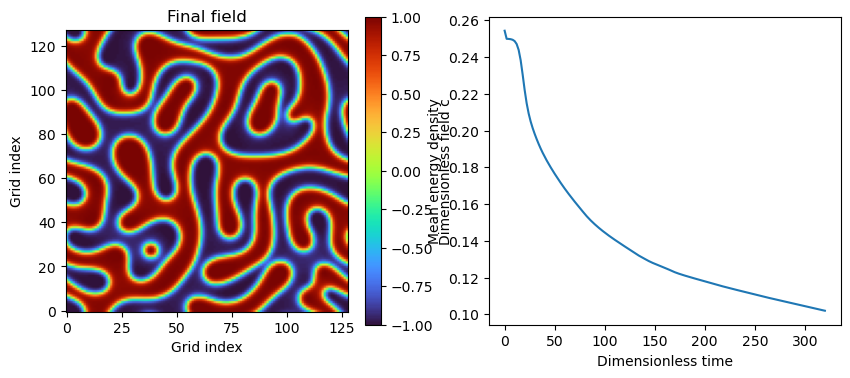

In [11]:
import matplotlib.pyplot as plt
values = np.asarray(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im = axes[0].imshow(c, origin="lower", cmap="turbo", vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[0], label="Dimensionless field c")
axes[0].set_title("Final field")
axes[0].set_xlabel("Grid index")
axes[0].set_ylabel("Grid index")
axes[1].plot(values[:, 1], values[:, 3])
axes[1].set_xlabel("Dimensionless time")
axes[1].set_ylabel("Mean energy density")
plt.show()

## 11. Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/spinodal_demo.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.